# 1. Введение в PINN: затухающий осциллятор

**Цель:** показать, что физика помогает в **экстраполяции**, то есть в прогнозе там, где измерений нет совсем. Оба подхода используют одну и ту же нейросеть, различается только функция потерь.

Уравнение затухающего осциллятора:
$$x''(t)+2\zeta x'(t)+x(t)=0,\qquad x(0)=1,\quad x'(0)=0.$$
Время и частота безразмерные, $0<\zeta<1$ задаёт затухание. Измерения есть только на начальном отрезке $t\in[0,4]$, а оцениваем модели на всём интервале $t\in[0,12]$, то есть и за пределами измерений.

PINN — это нейросеть, при обучении которой учитываются физические уравнения. Помимо ошибки на измерениях, мы штрафуем невязку уравнения в точках коллокации на всём интервале и отклонение от начальных условий.

**Источники.** Постановка этого примера вдохновлена записью в блоге Б. Мозли [So, what is a physics-informed neural network?](https://benmoseley.blog/my-research/so-what-is-a-physics-informed-neural-network/) и его [ноутбуком с PINN для гармонического осциллятора](https://github.com/benmoseley/harmonic-oscillator-pinn/blob/main/Harmonic%20oscillator%20PINN.ipynb).

In [1]:
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from torch import nn

torch.manual_seed(7)
np.random.seed(7)
torch.set_default_dtype(torch.float64)
print("PyTorch:", torch.__version__)

# Цветовая схема: тема seaborn «whitegrid», палитра husl и три собственных цвета
PINN_COLOR = "#5b5fb0"  # индиго: PINN
REFERENCE_COLOR = "#e3242b"  # красный, пунктир: точное решение
SAMPLES_COLOR = "#a1c9f4"  # пастельно-голубой: измерения, область экстраполяции
MLP_COLOR = "#36ada4"  # husl, бирюзовый: MLP, обученная на данных
INK_COLOR = "#262626"
GRID_COLOR = "#cccccc"
REFERENCE_STYLE = {"color": REFERENCE_COLOR, "linestyle": "--", "linewidth": 2.0}
OBS_STYLE = {
    "color": SAMPLES_COLOR,
    "edgecolors": INK_COLOR,
    "linewidths": 0.8,
    "s": 55,
    "zorder": 4,
}
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans", "Liberation Sans", "sans-serif"],
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.edgecolor": GRID_COLOR,
        "axes.linewidth": 1.25,
        "axes.titlesize": 12,
        "axes.titlecolor": INK_COLOR,
        "axes.labelsize": 11,
        "axes.labelcolor": INK_COLOR,
        "grid.color": GRID_COLOR,
        "grid.linewidth": 1.0,
        "text.color": INK_COLOR,
        "xtick.color": INK_COLOR,
        "ytick.color": INK_COLOR,
        "xtick.bottom": False,
        "ytick.left": False,
        "legend.frameon": True,
        "legend.framealpha": 0.8,
        "legend.edgecolor": GRID_COLOR,
        "legend.fontsize": 9,
        "lines.solid_capstyle": "round",
    }
)

PyTorch: 2.15.0


## 1. Эталонное решение и измерения только на начальном отрезке

Аналитическое решение используется только для оценки результатов. Обучающая выборка — 8 измерений на $t\in[0,4]$. Правее этого отрезка модели ничего не видят.

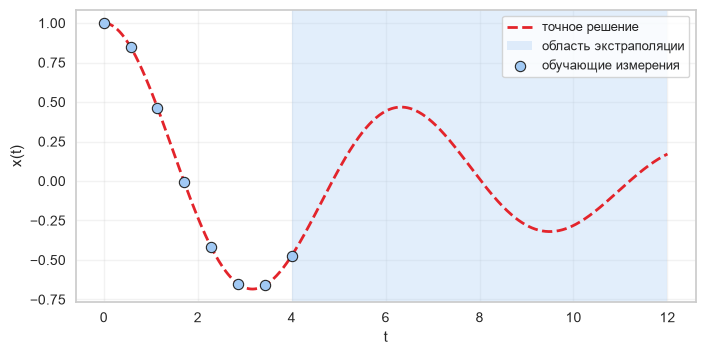

In [2]:
zeta = 0.12
T = 12.0  # весь интервал оценки
T_OBS = 4.0  # измерения только на [0, T_OBS]


def exact(t: np.ndarray) -> np.ndarray:
    wd = np.sqrt(1 - zeta**2)
    return np.exp(-zeta * t) * (np.cos(wd * t) + zeta / wd * np.sin(wd * t))


t_obs_np = np.linspace(0, T_OBS, 8)[:, None]
x_obs_np = exact(t_obs_np)
t_test_np = np.linspace(0, T, 500)[:, None]
x_test_np = exact(t_test_np)

plt.figure(figsize=(8, 3.8))
plt.plot(t_test_np, x_test_np, label="точное решение", **REFERENCE_STYLE)
plt.axvspan(
    T_OBS, T, color=SAMPLES_COLOR, alpha=0.3, linewidth=0, label="область экстраполяции"
)
plt.scatter(t_obs_np, x_obs_np, label="обучающие измерения", **OBS_STYLE)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 2. Общая постановка и обычное обучение на данных

Для честного сравнения у обеих моделей общее **всё, кроме функции потерь**: одинаковые архитектура, инициализация (фиксированный seed), оптимизатор, расписание шага обучения и число шагов.

Сеть — обычный MLP, который принимает время $t$ и предсказывает смещение $x$. Модели различаются только функцией потерь:

- **обучение с учителем:** среднеквадратичная ошибка на измерениях;
- **PINN:** та же ошибка плюс невязка уравнения в точках коллокации на всём интервале и ошибка начальных условий (следующий раздел).

In [3]:
WIDTH = 32
N_STEPS = 15000
LR = 3e-3
SEED = 7

LossFn = Callable[[nn.Module], tuple[torch.Tensor, dict[str, float]]]
Snapshot = tuple[int, np.ndarray, float]  # (шаг, предсказание на сетке, лосс)


class MLP(nn.Module):
    def __init__(self, width: int = WIDTH) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
            nn.Linear(width, 1),
        )

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        return self.net(
            2 * t / T - 1
        )  # масштабируем в [-1, 1], так обучение идёт лучше


# шаги, на которых сохраняем предсказание для анимации (чаще в начале обучения)
snap_steps = set(np.unique(np.geomspace(1, N_STEPS, 60).astype(int))) | {N_STEPS}
t_snap = torch.tensor(t_test_np)


def train(loss_fn: LossFn) -> tuple[MLP, list[Snapshot], dict[str, float]]:
    """Одинаковый цикл обучения для всех моделей: отличается только `loss_fn`.

    `loss_fn(model)` возвращает полный лосс и словарь его слагаемых для логирования.
    """
    torch.manual_seed(
        SEED
    )  # одинаковые начальные веса и одинаковая последовательность случайных чисел
    model = MLP()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, N_STEPS)
    snapshots: list[Snapshot] = []
    parts: dict[str, float] = {}
    for step in range(N_STEPS):
        loss, parts = loss_fn(model)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step + 1 in snap_steps:
            with torch.no_grad():
                snapshots.append((step + 1, model(t_snap).numpy(), loss.item()))
    return model, snapshots, parts


t_obs = torch.tensor(t_obs_np)
x_obs = torch.tensor(x_obs_np)


def data_loss(model: nn.Module) -> torch.Tensor:
    return ((model(t_obs) - x_obs) ** 2).mean()


def supervised_loss(model: nn.Module) -> tuple[torch.Tensor, dict[str, float]]:
    loss = data_loss(model)
    return loss, {"data": loss.item()}


data_model, _, parts = train(supervised_loss)
print(f"Лосс на данных: {parts['data']:.3e}")

Лосс на данных: 3.985e-17


## 3. PINN: та же сеть и то же обучение плюс уравнение

Меняется только функция потерь. Она состоит из трёх слагаемых:

- ошибка на измерениях, ровно как в модели с учителем;
- невязка уравнения $x''+2\zeta x'+x=0$ в точках коллокации на **всём** интервале $[0,12]$;
- ошибка начальных условий $\big(\hat x(0)-1\big)^2+\hat x'(0)^2$.

Сеть, инициализация, оптимизатор, расписание и число шагов те же, что в предыдущем разделе.

In [4]:
def derivatives(y: torch.Tensor, t: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    dy = torch.autograd.grad(y, t, torch.ones_like(y), create_graph=True)[0]
    d2y = torch.autograd.grad(dy, t, torch.ones_like(dy), create_graph=True)[0]
    return dy, d2y


def make_pinn_loss(zeta_eq: float = zeta, use_data: bool = True) -> LossFn:
    """Лосс PINN. `zeta_eq` — затухание в уравнении, `use_data` включает или выключает измерения."""

    def pinn_loss(model: nn.Module) -> tuple[torch.Tensor, dict[str, float]]:
        tc = (T * torch.rand(256, 1)).requires_grad_(True)  # точки на всём [0, T]
        xp = model(tc)
        dx, d2x = derivatives(xp, tc)
        residual = d2x + 2 * zeta_eq * dx + xp
        loss_phys = (residual**2).mean()

        t0 = torch.zeros(1, 1, requires_grad=True)  # начальные условия x(0)=1, x'(0)=0
        x0 = model(t0)
        dx0, _ = derivatives(x0, t0)
        loss_ic = ((x0 - 1) ** 2).mean() + (dx0**2).mean()

        loss_data = data_loss(model) if use_data else torch.zeros(())
        parts = {
            "phys": loss_phys.item(),
            "ic": loss_ic.item(),
            "data": loss_data.item(),
        }
        return loss_phys + loss_ic + loss_data, parts

    return pinn_loss


pinn, snapshots, parts = train(make_pinn_loss())
print(
    f"Лосс невязки уравнения: {parts['phys']:.3e}, лосс НУ: {parts['ic']:.3e}, "
    f"лосс на данных: {parts['data']:.3e}"
)

Лосс невязки уравнения: 3.241e-05, лосс НУ: 1.740e-09, лосс на данных: 7.294e-08


## 4. Сравнение: интерполяция и экстраполяция

Сравниваем обе модели с эталоном на плотной сетке. Ошибку считаем отдельно на отрезке с измерениями $[0,4]$ и в области экстраполяции $(4,12]$. Эталонные значения при $t>4$ в обучении не использовались.

RMSE            [0, 4] (данные)   (4, 12] (экстраполяция)
с учителем:      0.0034            0.4936
PINN      :      0.0002            0.0041


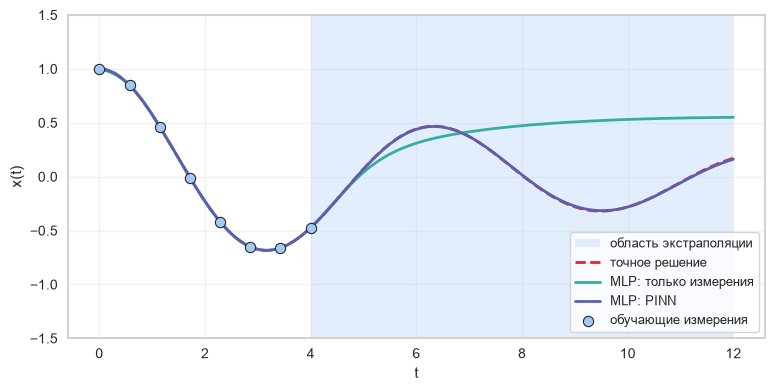

In [5]:
t_test = torch.tensor(t_test_np)
with torch.no_grad():
    pred_data = data_model(t_test).numpy()
    pred_pinn = pinn(t_test).numpy()


def rmse(pred: np.ndarray, mask: np.ndarray) -> float:
    return np.sqrt(np.mean((pred[mask] - x_test_np[mask]) ** 2))


inside = t_test_np[:, 0] <= T_OBS
outside = ~inside
print("RMSE            [0, 4] (данные)   (4, 12] (экстраполяция)")
for name, pred in [("с учителем", pred_data), ("PINN      ", pred_pinn)]:
    print(f"{name}:      {rmse(pred, inside):.4f}            {rmse(pred, outside):.4f}")

plt.figure(figsize=(9, 4.2))
plt.axvspan(
    T_OBS, T, color=SAMPLES_COLOR, alpha=0.3, linewidth=0, label="область экстраполяции"
)
plt.plot(t_test_np, x_test_np, label="точное решение", **REFERENCE_STYLE)
plt.plot(t_test_np, pred_data, color=MLP_COLOR, lw=2, label="MLP: только измерения")
plt.plot(t_test_np, pred_pinn, color=PINN_COLOR, lw=2, label="MLP: PINN")
plt.scatter(t_obs_np, x_obs_np, label="обучающие измерения", **OBS_STYLE)
plt.ylim(-1.5, 1.5)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 5. Как обучается PINN: анимация

Во время обучения мы сохраняли предсказание PINN. Превратим эти снимки в GIF: сначала сеть далека от решения, затем подстраивается под измерения и начальные условия и, наконец, продолжает колебания в области экстраполяции.

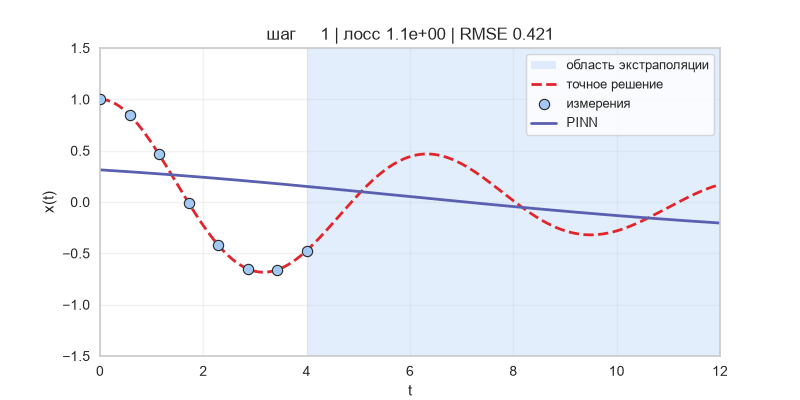

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(
    T_OBS,
    T,
    color=SAMPLES_COLOR,
    alpha=0.3,
    linewidth=0,
    label="область экстраполяции",
)
ax.plot(t_test_np, x_test_np, label="точное решение", **REFERENCE_STYLE)
ax.scatter(t_obs_np, x_obs_np, label="измерения", **OBS_STYLE)
(line,) = ax.plot([], [], color=PINN_COLOR, lw=2, label="PINN")
title = ax.set_title("")
ax.set_ylim(-1.5, 1.5)
ax.set_xlim(0, T)
ax.set_xlabel("t")
ax.set_ylabel("x(t)")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)


def update(i: int):
    step, pred, loss = snapshots[i]
    line.set_data(t_test_np[:, 0], pred[:, 0])
    err = np.sqrt(np.mean((pred - x_test_np) ** 2))
    title.set_text(f"шаг {step:>5d} | лосс {loss:.1e} | RMSE {err:.3f}")
    return line, title


frames = list(range(len(snapshots))) + [len(snapshots) - 1] * 10
anim = FuncAnimation(fig, update, frames=frames, blit=False)
gif_path = Path("../assets/oscillator_pinn_evolution.gif")
gif_path.parent.mkdir(exist_ok=True)
anim.save(gif_path, writer=PillowWriter(fps=8))
plt.close(fig)
display(Image(filename=gif_path))

## 6. Эксперименты для обсуждения

Два варианта PINN, обученные точно так же, как раньше:

- **неверное $\zeta$:** в уравнении стоит $\zeta=0.25$ вместо истинного $0.12$, а измерения по-прежнему взяты из истинного решения;
- **без измерений:** функция потерь содержит только невязку уравнения и начальные условия.

RMSE                      [0, 4] (данные)   (4, 12] (экстраполяция)
PINN:                     0.0002            0.0041
PINN, неверное ζ = 0.25:  0.0334            0.1317
PINN, без измерений:      0.0006            0.0019


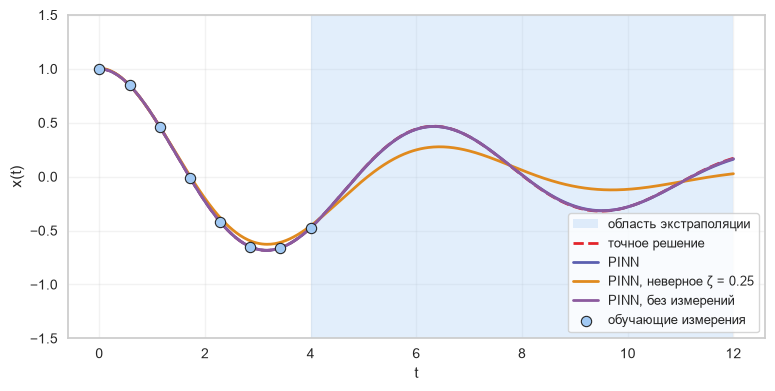

In [7]:
ZETA_WRONG = 0.25
WRONG_COLOR = "#e08a1e"  # оранжевый: PINN с неверным уравнением
PHYSICS_COLOR = "#8c5a9e"  # фиолетовый: PINN без измерений

variants: dict[str, tuple[nn.Module, str]] = {
    f"PINN, неверное ζ = {ZETA_WRONG}": (
        train(make_pinn_loss(zeta_eq=ZETA_WRONG))[0],
        WRONG_COLOR,
    ),
    "PINN, без измерений": (
        train(make_pinn_loss(use_data=False))[0],
        PHYSICS_COLOR,
    ),
}

plt.figure(figsize=(9, 4.2))
plt.axvspan(
    T_OBS, T, color=SAMPLES_COLOR, alpha=0.3, linewidth=0, label="область экстраполяции"
)
plt.plot(t_test_np, x_test_np, label="точное решение", **REFERENCE_STYLE)
plt.plot(t_test_np, pred_pinn, color=PINN_COLOR, lw=2, label="PINN")
print("RMSE                      [0, 4] (данные)   (4, 12] (экстраполяция)")
print(
    f"PINN:                     {rmse(pred_pinn, inside):.4f}            {rmse(pred_pinn, outside):.4f}"
)
for name, (model, color) in variants.items():
    with torch.no_grad():
        pred = model(t_test).numpy()
    plt.plot(t_test_np, pred, color=color, lw=2, label=name)
    print(
        f"{name + ':':<25} {rmse(pred, inside):.4f}            {rmse(pred, outside):.4f}"
    )
plt.scatter(t_obs_np, x_obs_np, label="обучающие измерения", **OBS_STYLE)
plt.ylim(-1.5, 1.5)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

**Неверное $\zeta$.** Теперь в функции потерь два противоречащих друг другу требования — данные и неверное уравнение, — и сеть ищет компромисс. Она уже не проходит точно через измерения, а в области экстраполяции колебания затухают слишком быстро. PINN хороша ровно настолько, насколько хороша заложенная в неё физика.

**Без измерений.** PINN всё равно восстанавливает решение, и ошибка экстраполяции не хуже, чем с данными. Уравнение и начальные условия уже однозначно задают решение, поэтому здесь измерения мало что добавляют. Они важны, когда уравнение или его параметры известны неточно. Разница между 0.0019 и 0.0041 лежит в пределах того, что меняется при другом seed, поэтому мы не придаём ей значения.

## Что показывает пример

- Модель, обученная с учителем, подстраивается под измерения, но вне их ничего не знает о динамике и уходит от решения.
- При тех же архитектуре, инициализации и обучении PINN через функцию потерь знает ещё и уравнение с начальными условиями, поэтому продолжает затухающие колебания за пределами данных.
- Это иллюстрация, а не гарантия: результат зависит от задачи, данных и оптимизации. Смотрите на независимую ошибку, а не только на лосс.